In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

df = pd.read_csv('/content/Iris - Iris.csv')

In [ ]:

print("First five records of the dataset:")
display(df.head())

First five records of the dataset:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:

print("\nMissing values in the dataset:")
display(df.isnull().sum())


Missing values in the dataset:


,0
Id,0
SepalLengthCm,0
SepalWidthCm,0
PetalLengthCm,0
PetalWidthCm,0
Species,0


In [ ]:

print("\nDescriptive statistics of numerical attributes:")
display(df.describe())


Descriptive statistics of numerical attributes:


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,75.500000,5.843333,3.054000,3.758667,1.198667
std,43.445368,0.828066,0.433594,1.764420,0.763161
min,1.000000,4.300000,2.000000,1.000000,0.100000
25%,38.250000,5.100000,2.800000,1.600000,0.300000
50%,75.500000,5.800000,3.000000,4.350000,1.300000
75%,112.750000,6.400000,3.300000,5.100000,1.800000
max,150.000000,7.900000,4.400000,6.900000,2.500000


Distribution of Species Classes:
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


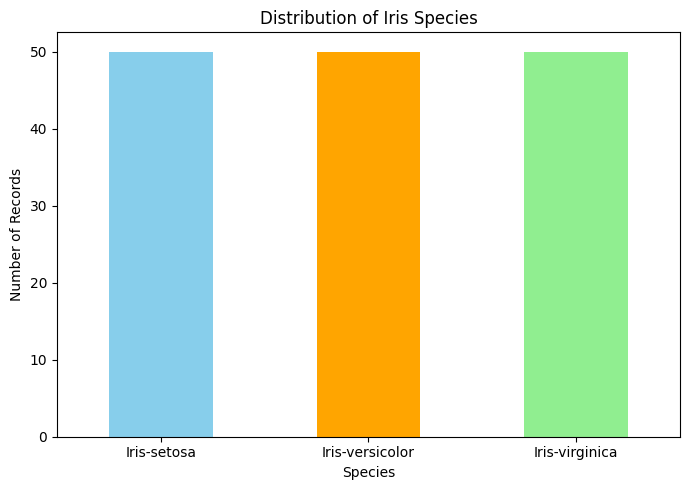

In [ ]:
print("Distribution of Species Classes:")
print(df["Species"].value_counts())

# Plot distribution of Species
plt.figure(figsize=(7, 5))
df["Species"].value_counts().plot(
    kind="bar",
    color=["skyblue", "orange", "lightgreen"]
)

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:

X = df.drop(['Id', 'Species'], axis=1)
y = df['Species']

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (150, 4)
Target (y) shape: (150,)


In [ ]:

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training set size: {len(X_train)} samples")
print(f"Testing set size: {len(X_test)} samples")

Training set size: 120 samples
Testing set size: 30 samples


In [ ]:
# Implement a Decision Tree Classifier with a specified maximum depth
# You can adjust max_depth as needed
dtree = DecisionTreeClassifier(max_depth=3, random_state=42)
dtree.fit(X_train, y_train)

print(f"Decision Tree Classifier trained with max_depth={dtree.max_depth}")

Decision Tree Classifier trained with max_depth=3


In [ ]:
# Predict the species of the test data and calculate the classification accuracy
y_pred = dtree.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)

print(f"Classification Accuracy: {accuracy:.4f}")

Classification Accuracy: 1.0000


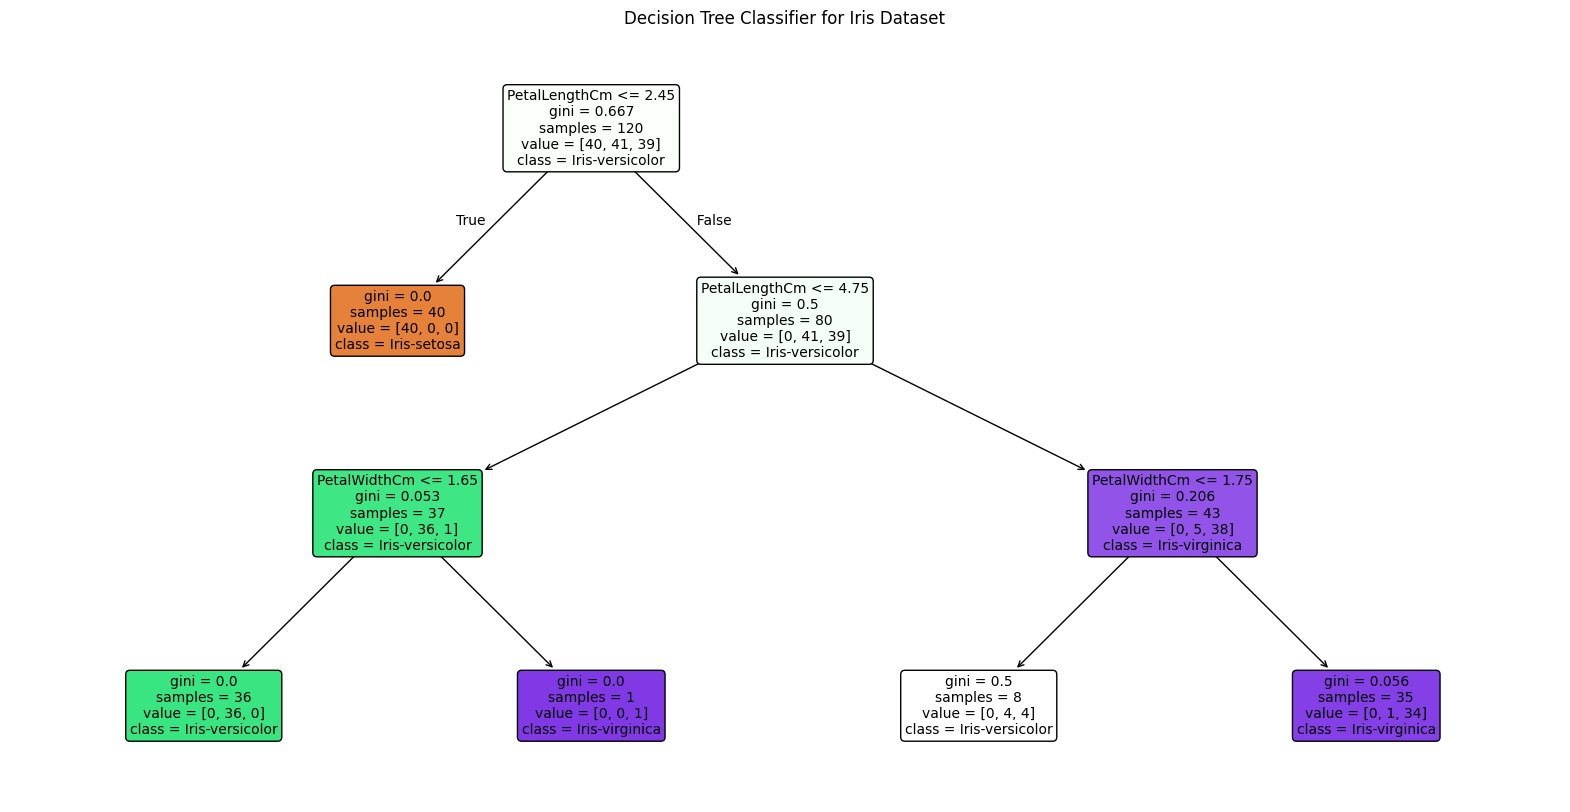

In [ ]:
# Plot and display the resulting Decision Tree with feature names and class names
plt.figure(figsize=(20, 10))
plot_tree(dtree,
          feature_names=X.columns.tolist(),
          class_names=dtree.classes_.tolist(),
          filled=True,
          rounded=True,
          fontsize=10)
plt.title('Decision Tree Classifier for Iris Dataset')
plt.show()